# AlexNet 2012 on Tiny ImageNet

Reproduces AlexNet (Krizhevsky et al., 2012), trained on Tiny ImageNet 64x64.

In [24]:
# Standard library
import os
import shutil
import time
import urllib.request
import zipfile

# Third-party
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [25]:
URL       = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
DATA_ROOT = "data"
ZIP_PATH  = os.path.join(DATA_ROOT, "tiny-imagenet-200.zip")
DATA_DIR  = os.path.join(DATA_ROOT, "tiny-imagenet-200")

NUM_CLASSES = 200
NUM_EPOCHS  = 60
LR          = 0.02      # linearly scaled from paper: LR=0.01 BS=128
BATCH_SIZE  = 256
WEIGHT_DECAY = 5e-4
MOMENTUM    = 0.9
SEED        = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

### TinyImagenet Dataset

In [26]:
if not (os.path.isdir(DATA_DIR) and os.listdir(DATA_DIR)):
    os.makedirs(DATA_ROOT, exist_ok=True)
    print("Downloading Tiny ImageNet...")
    urllib.request.urlretrieve(URL, ZIP_PATH + ".part")
    os.replace(ZIP_PATH + ".part", ZIP_PATH)

    print("Extracting...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_ROOT)

    os.remove(ZIP_PATH)
    print("Done:", DATA_DIR)

# torchvision.datasets.ImageFolder needs one subfolder per class.
# Tiny ImageNet has its train folder structured that way,
# but the val one is flat with a val_annotations.txt
val = os.path.join(DATA_DIR, "val")
if os.path.isdir(os.path.join(val, "images")):
    for line in open(os.path.join(val, "val_annotations.txt")):
        name, cls, *_ = line.strip().split("\t")
        os.makedirs(os.path.join(val, cls), exist_ok=True)
        shutil.move(os.path.join(val, "images", name), os.path.join(val, cls, name))
    shutil.rmtree(os.path.join(val, "images"))

### Transforms

In [27]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomCrop(64, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

### Datasets & DataLoaders

In [28]:
train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
val_dataset   = datasets.ImageFolder(os.path.join(DATA_DIR, "val"),   transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=12, pin_memory=True, prefetch_factor=4, persistent_workers=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=4, pin_memory=True, prefetch_factor=4, persistent_workers=True,
)

print(f"train: {len(train_dataset)} imgs, {len(train_loader)} batches")
print(f"val:   {len(val_dataset)} imgs, {len(val_loader)} batches")

train: 100000 imgs, 391 batches
val:   10000 imgs, 40 batches


### AlexNet 2012

In [ ]:
class AlexNet(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()

        # (original paper split conv layers between 2 GPUs due to hardware constraints at the time.)
        self.features = nn.Sequential(

            # AlexNet's conv1 and pool1 were designed for 224×224 input.
            # At 64×64 it would over-downsample: 64 -> 15 -> 7, and the trunk
            # ends at 1×1 instead of the 6×6 the classifier expects.
            # so we modify them:
            #   conv1 (11, 4, 2) -> (11, 2, 2)
            #   pool1 (3, 2, 0) -> (3, 1, 0) 
            
            # heavy downsampling to reduce compute 
            nn.Conv2d(3, 96, kernel_size=11, stride=2, padding=2), # (64 -> 29)  
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),

            # downsampling
            nn.MaxPool2d(kernel_size=3, stride=1), # (29 -> 27)                

            # feature extraction
            nn.Conv2d(96, 256, kernel_size=5, padding=2), # (27 -> 27)
            nn.ReLU(inplace=True),
            nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0),

            # downsampling
            nn.MaxPool2d(kernel_size=3, stride=2), # (27 -> 13)

            # feature extraction
            nn.Conv2d(256, 384, kernel_size=3, padding=1), # (13 -> 13)
            nn.ReLU(inplace=True),

            # feature extraction
            nn.Conv2d(384, 384, kernel_size=3, padding=1), # (13 -> 13)
            nn.ReLU(inplace=True),

            # feature extraction
            nn.Conv2d(384, 256, kernel_size=3, padding=1), # (13 -> 13)
            nn.ReLU(inplace=True),

            # downsampling
            nn.MaxPool2d(kernel_size=3, stride=2), # (13 -> 6) -> so 6x6
        )

        # this allows input sizes other than 64x64 to work as well.
        # self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

        self.classifier = nn.Sequential(
            nn.Linear(256*6*6, 4096), # <-- classifier
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        # x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

### Training

In [30]:
import lightning as L

class LitAlexNet(L.LightningModule):
    def __init__(self, num_classes, lr, momentum, weight_decay, max_epochs):
        super().__init__()
        self.save_hyperparameters()
        self.net = AlexNet(num_classes=num_classes)
        self.net = torch.compile(self.net)   
        self.criterion = nn.CrossEntropyLoss()
        self.history = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}

    def forward(self, x): return self.net(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        self.log(f"{stage}_loss", loss, on_epoch=True, batch_size=x.size(0))
        self.log(f"{stage}_acc", (logits.argmax(1) == y).float().mean(),
                 on_epoch=True, batch_size=x.size(0))
        return loss

    def training_step(self, b, _):   return self._shared_step(b, "train")
    def validation_step(self, b, _): return self._shared_step(b, "val")

    # logging stuff for the graph
    def on_validation_epoch_end(self):
        if self.trainer.sanity_checking: return
        m = self.trainer.callback_metrics
        tl, ta = m["train_loss"].item(), m["train_acc"].item() * 100
        vl, va = m["val_loss"].item(),   m["val_acc"].item() * 100
        self.history["train_loss"].append(tl); self.history["train_acc"].append(ta)
        self.history["val_loss"].append(vl);   self.history["val_acc"].append(va)
        e = self.trainer.current_epoch + 1
        print(f"Epoch {e:2d}/{self.trainer.max_epochs} | "
              f"Train {tl:.4f} {ta:5.2f}% | Val {vl:.4f} {va:5.2f}%")

    def configure_optimizers(self):
        opt = optim.SGD(self.parameters(), lr=self.hparams.lr,
                        momentum=self.hparams.momentum,
                        weight_decay=self.hparams.weight_decay)
        return {"optimizer": opt,
                "lr_scheduler": optim.lr_scheduler.CosineAnnealingLR(opt, T_max=self.hparams.max_epochs)}


model = LitAlexNet(NUM_CLASSES, LR, MOMENTUM, WEIGHT_DECAY, NUM_EPOCHS)

trainer = L.Trainer(
    max_epochs=NUM_EPOCHS, accelerator="gpu", devices=1,
    precision="16-mixed", enable_checkpointing=False,
    enable_model_summary=False, logger=False, enable_progress_bar=False,
)
trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)

history = model.history
print(f"\nDone. Best val acc: {max(history['val_acc']):.2f}%")

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/home/simone/Desktop/ROCM_CODING/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch  1/60 | Train 5.2990  0.00% | Val 5.2934  0.50%
Epoch  2/60 | Train 5.0653  3.12% | Val 5.0762  1.53%
Epoch  3/60 | Train 4.6454  2.50% | Val 4.7885  3.77%
Epoch  4/60 | Train 4.4648 12.50% | Val 4.5123  6.71%
Epoch  5/60 | Train 4.4889  6.25% | Val 4.2561  9.97%
Epoch  6/60 | Train 4.0517 12.50% | Val 3.8397 15.79%
Epoch  7/60 | Train 3.8448 18.13% | Val 3.7300 17.03%
Epoch  8/60 | Train 3.8241 19.38% | Val 3.4820 21.37%
Epoch  9/60 | Train 3.3335 20.62% | Val 3.3050 24.48%
Epoch 10/60 | Train 3.2662 24.38% | Val 3.2162 26.88%
Epoch 11/60 | Train 2.8621 31.87% | Val 3.0743 29.46%
Epoch 12/60 | Train 3.1602 26.88% | Val 2.9515 31.70%
Epoch 13/60 | Train 2.7255 31.87% | Val 2.8785 32.43%
Epoch 14/60 | Train 2.7244 33.75% | Val 2.8617 34.03%
Epoch 15/60 | Train 2.5518 35.63% | Val 2.7217 36.23%
Epoch 16/60 | Train 2.6830 30.00% | Val 2.6751 37.09%
Epoch 17/60 | Train 2.5187 40.62% | Val 2.6401 37.86%
Epoch 18/60 | Train 2.4764 35.00% | Val 2.5981 39.29%
Epoch 19/60 | Train 2.3485 4

`Trainer.fit` stopped: `max_epochs=60` reached.


Epoch 60/60 | Train 0.1311 95.63% | Val 2.8974 48.29%

Done. Best val acc: 48.43%


### Training curves

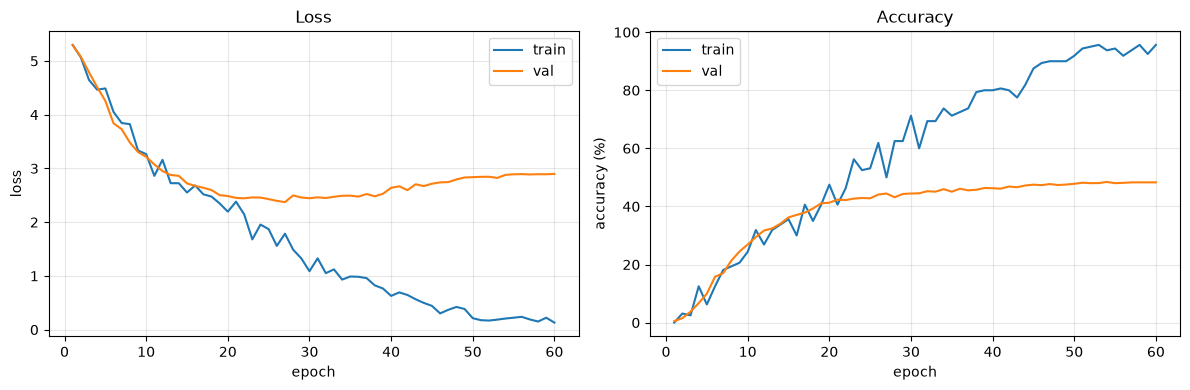

In [31]:
import matplotlib.pyplot as plt 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history["train_loss"]) + 1)

ax1.plot(epochs, history["train_loss"], label="train")
ax1.plot(epochs, history["val_loss"],   label="val")
ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, history["train_acc"], label="train")
ax2.plot(epochs, history["val_acc"],   label="val")
ax2.set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()